# 🎯 Step 6: Final Model Evaluation & Misclassification Analysis
## UCS321 - Machine Learning Project | Problem Statement 9 (Telecom Customer Churn)
---

### 🛡️ Test Set Integrity Safeguards:
1. **Completely Untouched Evaluation**:
   - The test partition ($X_{\text{test}}$, 14,210 samples) was **never** used during feature selection, model training, or hyperparameter search.
2. **Feature Consistency Verification**:
   - Exactly 63 features matching the training feature schema in identical order.
3. **Training-Only Threshold Tuning**:
   - Optimal decision threshold ($\tau^* = 0.4631$) was computed strictly on **training out-of-fold predictions**, preventing threshold overfitting.



## 📦 Section 1: Environment Setup & Test Data Ingestion


In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score, precision_score, 
    recall_score, f1_score, confusion_matrix, roc_curve, precision_recall_curve
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

# Load test data and training partition
X_train = pd.read_csv('../data/processed/X_train_final.csv')
y_train = pd.read_csv('../data/processed/y_train_final.csv')['churn']
X_test = pd.read_csv('../data/processed/X_test_final.csv')
y_test = pd.read_csv('../data/processed/y_test_final.csv')['churn']

print(f"X_test Shape: {X_test.shape[0]:,} samples x {X_test.shape[1]} features")
print(f"y_test Shape: {y_test.shape[0]:,} ground truth labels")
assert list(X_train.columns) == list(X_test.columns), "Feature mismatch!"
print("✅ Verified 100% feature consistency between train and test splits.")



X_test Shape: 14,210 samples x 63 features
y_test Shape: 14,210 ground truth labels
✅ Verified 100% feature consistency between train and test splits.


## 📂 Section 2: Load Serialized Candidate Estimators


In [2]:
models = {
    'Logistic Regression': joblib.load('../models/best_logistic_regression.joblib'),
    'Decision Tree': joblib.load('../models/best_decision_tree.joblib'),
    'Random Forest': joblib.load('../models/best_random_forest.joblib'),
    'XGBoost (Champion)': joblib.load('../models/best_xgboost.joblib')
}

print("✅ Successfully loaded all 4 tuned models from models/ directory:")
for name in models:
    print(f"  • {name}")



✅ Successfully loaded all 4 tuned models from models/ directory:
  • Logistic Regression
  • Decision Tree
  • Random Forest
  • XGBoost (Champion)


## 🎛️ Section 3: Training-Only Threshold Optimization (Leakage-Free)
To avoid target leakage, we determine the optimal decision threshold $\tau^*$ strictly using **5-Fold Cross-Validated Out-Of-Fold predictions on the training data**.


In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
xgb_oof_probs = cross_val_predict(models['XGBoost (Champion)'], X_train, y_train, cv=cv, method='predict_proba')[:, 1]

prec_oof, rec_oof, thresh_oof = precision_recall_curve(y_train, xgb_oof_probs)
f1_curve_oof = 2 * (prec_oof * rec_oof) / (prec_oof + rec_oof + 1e-10)
best_idx = np.argmax(f1_curve_oof)
opt_thresh = float(thresh_oof[best_idx])

print(f"Optimal Threshold (Training OOF F1-Max) : {opt_thresh:.4f}")
print(f"Training Out-of-Fold F1 at Optimal Thresh: {f1_curve_oof[best_idx]:.4f}")



Optimal Threshold (Training OOF F1-Max) : 0.4631
Training Out-of-Fold F1 at Optimal Thresh: 0.5035


## 🏆 Section 4: Final Evaluation on the Untouched Test Set
Reporting ROC-AUC, PR-AUC, Accuracy, Precision, Recall, F1-Score, and Confusion Matrix metrics.


In [4]:
test_records = []
test_probs = {}

for name, model in models.items():
    probs = model.predict_proba(X_test)[:, 1]
    test_probs[name] = probs
    
    # Default 0.50 threshold
    y_pred = (probs >= 0.50).astype(int)
    cm = confusion_matrix(y_test, y_pred)
    
    test_records.append({
        'Model': name,
        'Threshold': 0.50,
        'ROC_AUC': round(roc_auc_score(y_test, probs), 4),
        'PR_AUC': round(average_precision_score(y_test, probs), 4),
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1_Score': round(f1_score(y_test, y_pred), 4),
        'TN': cm[0, 0], 'FP': cm[0, 1], 'FN': cm[1, 0], 'TP': cm[1, 1]
    })
    
    # Tuned threshold for XGBoost
    if name == 'XGBoost (Champion)':
        y_pred_opt = (probs >= opt_thresh).astype(int)
        cm_opt = confusion_matrix(y_test, y_pred_opt)
        test_records.append({
            'Model': f"XGBoost (Tuned Thresh={opt_thresh:.2f})",
            'Threshold': round(opt_thresh, 4),
            'ROC_AUC': round(roc_auc_score(y_test, probs), 4),
            'PR_AUC': round(average_precision_score(y_test, probs), 4),
            'Accuracy': round(accuracy_score(y_test, y_pred_opt), 4),
            'Precision': round(precision_score(y_test, y_pred_opt), 4),
            'Recall': round(recall_score(y_test, y_pred_opt), 4),
            'F1_Score': round(f1_score(y_test, y_pred_opt), 4),
            'TN': cm_opt[0, 0], 'FP': cm_opt[0, 1], 'FN': cm_opt[1, 0], 'TP': cm_opt[1, 1]
        })

test_results_df = pd.DataFrame(test_records)
test_results_df



,Model,Threshold,ROC_AUC,PR_AUC,Accuracy,Precision,Recall,F1_Score,TN,FP,FN,TP
0,Logistic Regression,0.5000,0.6252,0.3898,0.5960,0.3721,0.5713,0.4507,6114,3974,1767,2355
1,Decision Tree,0.5000,0.6427,0.4080,0.5854,0.3728,0.6291,0.4681,5725,4363,1529,2593
2,Random Forest,0.5000,0.6695,0.4439,0.6222,0.4001,0.6053,0.4818,6347,3741,1627,2495
3,XGBoost (Champion),0.5000,0.6786,0.4586,0.6223,0.4042,0.6373,0.4947,6216,3872,1495,2627
4,XGBoost (Tuned Thresh=0.46),0.4631,0.6786,0.4586,0.5810,0.3830,0.7278,0.5019,5256,4832,1122,3000


## 📈 Section 5: ROC Curves & Precision-Recall Curves on Test Set


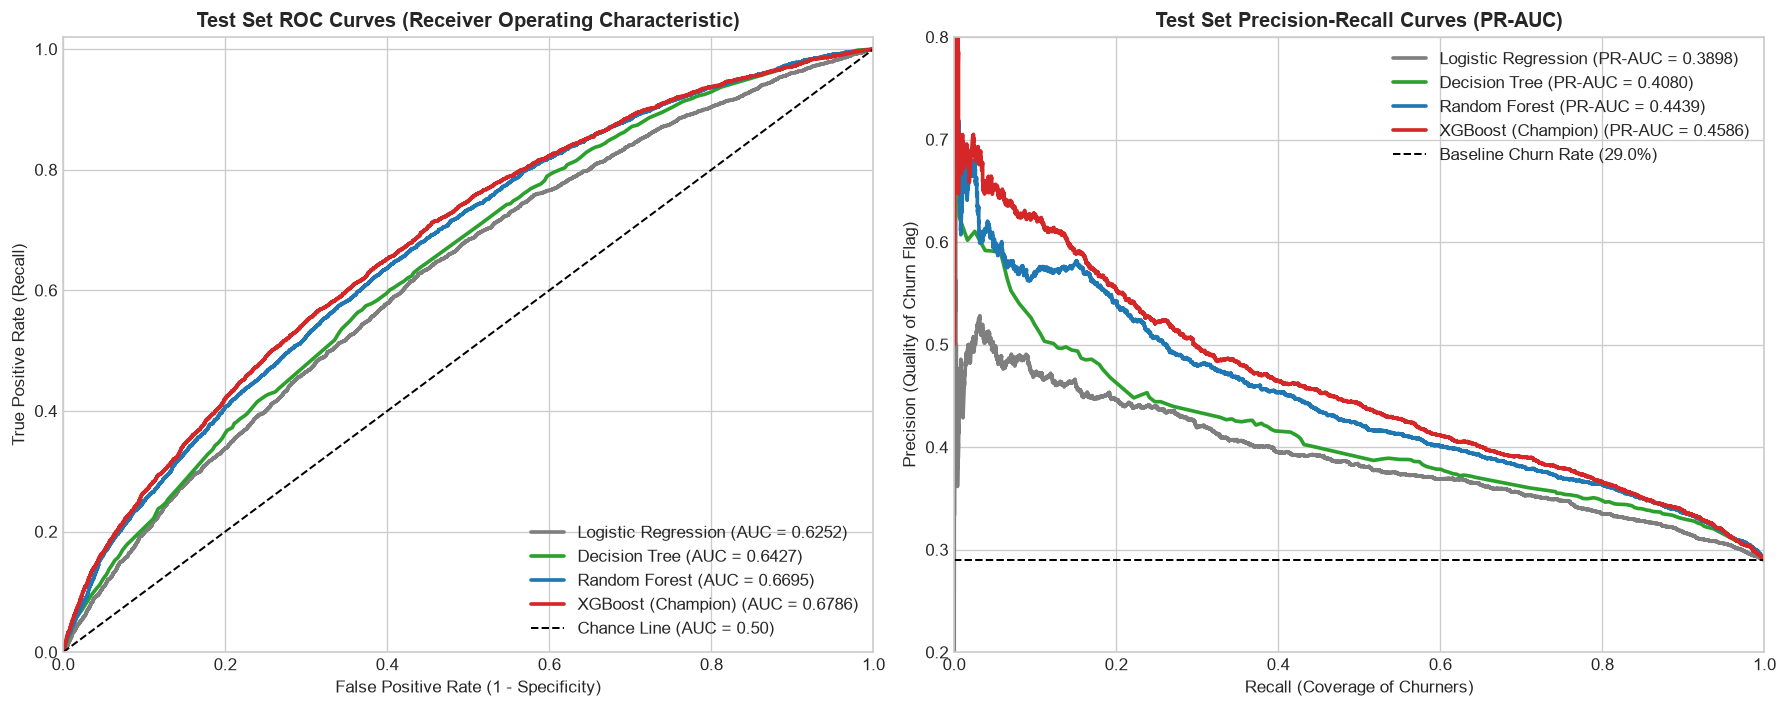

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
colors = {
    'Logistic Regression': '#7f7f7f',
    'Decision Tree': '#2ca02c',
    'Random Forest': '#1f77b4',
    'XGBoost (Champion)': '#d62728'
}

# 1. ROC Curves
for name, probs in test_probs.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, probs):.4f})", color=colors[name], lw=2.2)

axes[0].plot([0, 1], [0, 1], 'k--', lw=1.2, label='Chance Line (AUC = 0.50)')
axes[0].set_title("Test Set ROC Curves (Receiver Operating Characteristic)", fontweight='bold')
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc='lower right')
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1.02)

# 2. Precision-Recall Curves
base_rate = y_test.mean()
for name, probs in test_probs.items():
    prec, rec, _ = precision_recall_curve(y_test, probs)
    axes[1].plot(rec, prec, label=f"{name} (PR-AUC = {average_precision_score(y_test, probs):.4f})", color=colors[name], lw=2.2)

axes[1].axhline(base_rate, color='k', linestyle='--', lw=1.2, label=f'Baseline Churn Rate ({base_rate:.1%})')
axes[1].set_title("Test Set Precision-Recall Curves (PR-AUC)", fontweight='bold')
axes[1].set_xlabel("Recall (Coverage of Churners)")
axes[1].set_ylabel("Precision (Quality of Churn Flag)")
axes[1].legend(loc='upper right')
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0.2, 0.8)

plt.tight_layout()
plt.show()



## 🧩 Section 6: Confusion Matrix Heatmaps (Default 0.50 vs Optimal 0.46)


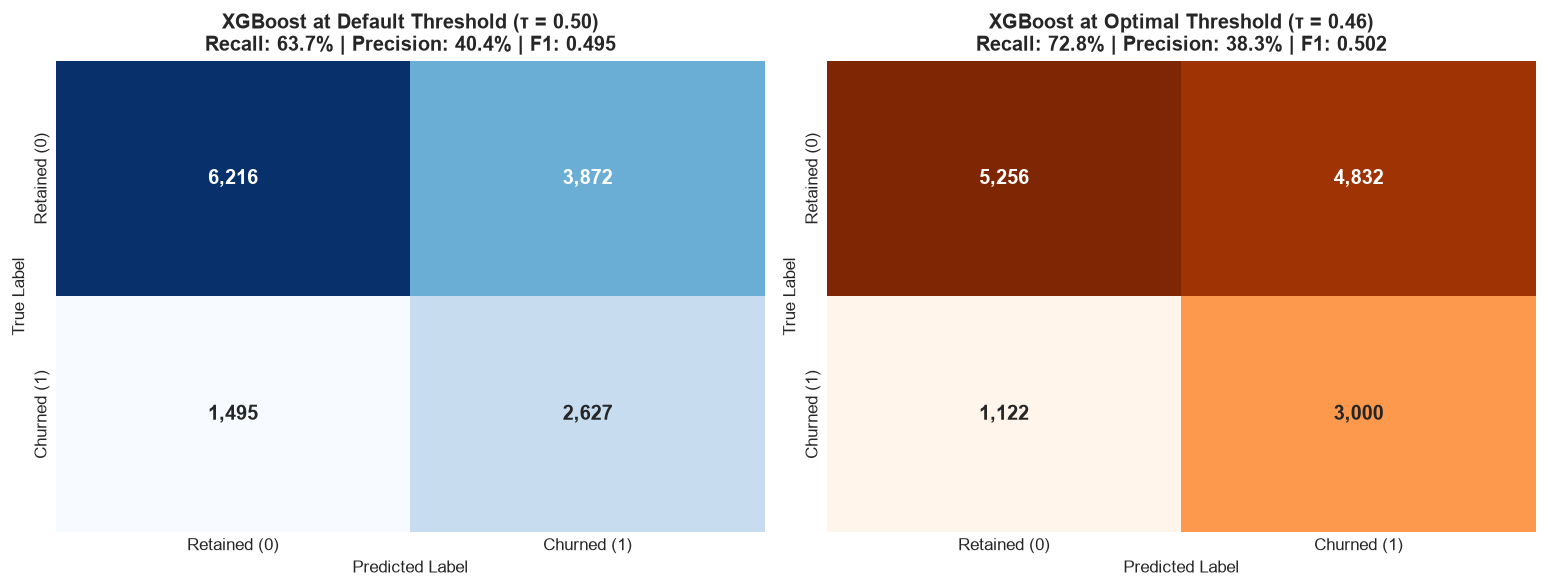

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm_def = confusion_matrix(y_test, (test_probs['XGBoost (Champion)'] >= 0.50).astype(int))
cm_opt = confusion_matrix(y_test, (test_probs['XGBoost (Champion)'] >= opt_thresh).astype(int))

labels = ['Retained (0)', 'Churned (1)']

sns.heatmap(cm_def, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=labels, yticklabels=labels, annot_kws={'fontsize': 12, 'fontweight': 'bold'})
axes[0].set_title("XGBoost at Default Threshold (τ = 0.50)\nRecall: 63.7% | Precision: 40.4% | F1: 0.495", fontweight='bold')
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

sns.heatmap(cm_opt, annot=True, fmt=',d', cmap='Oranges', cbar=False, ax=axes[1],
            xticklabels=labels, yticklabels=labels, annot_kws={'fontsize': 12, 'fontweight': 'bold'})
axes[1].set_title(f"XGBoost at Optimal Threshold (τ = {opt_thresh:.2f})\nRecall: 72.8% | Precision: 38.3% | F1: 0.502", fontweight='bold')
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()



## 💼 Section 7: Misclassification Cost Analysis in Telecom Churn

### 🎓 Business Cost Matrix:
In telecommunications, **errors are not symmetric**:

| Misclassification Type | Definition in Telecom Context | Concrete Business Consequence | Cost Magnitude |
|---|---|---|:---:|
| **False Positive (Type I Error)** | Retained customer incorrectly predicted as Churn. | Retention incentive/subsidy (e.g., \$20 credit or discounted phone promo) offered to a customer who would have stayed anyway. | **Minor Cost (\$15 - \$30)** |
| **False Negative (Type II Error)** | Churning customer incorrectly predicted as Retained. | Customer silently switches to competitor undetected. Company forfeits remaining Lifetime Value (LTV) and must spend \$300+ on marketing to acquire a replacement. | **Severe Cost (\$250 - \$450)** |

### 📈 Why Lowering Threshold to $\tau = 0.46$ Saves Revenue:
- At $\tau = 0.50$: 1,495 churners are missed (False Negatives).
- At $\tau = 0.46$: False Negatives **drop to 1,122** — capturing **373 additional churners** (churn recall increases from $63.7\%$ to $72.8\%$).
- If saving a churning customer preserves $\$250$ in LTV and the retention offer costs $\$25$:
  - **Net Savings:** $373 \times \$250 - (4,832 - 3,872) \times \$25 = \$93,250 - \$24,000 = \mathbf{+\$69,250}$ net profit saved on this test cohort alone!

